# EDA B: Thời tiết

Các phép kiểm tra dùng chung nằm trong `src/eda/helpers.py`. Notebook chỉ giữ phần phân tích và nhận xét.

In [1]:
from pathlib import Path
import sys
project_root = next((folder for folder in (Path.cwd(), *Path.cwd().parents) if (folder / 'data/Metro_Interstate_Traffic_Volume.csv').is_file()))
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import Markdown, display
from sklearn.model_selection import TimeSeriesSplit
from src.eda import helpers as eda_tools
from src.features import CONFIG_A, CONFIG_B, CONFIG_C, HISTORY_FEATURES, WEATHER_GROUPS
SEED = eda_tools.SEED
MIN_GROUP = eda_tools.MIN_GROUP
MIN_HISTORY = eda_tools.MIN_HISTORY

In [2]:
context = eda_tools.load_context(project_root)
train = context['train']

In [3]:
rain_count = int(context['rain_audit'].loc[context['rain_audit'].rule.eq('weather_main = Rain'), 'zero_rain_rows'].iloc[0])
display(Markdown(f'**Mục tiêu:** khảo sát chất lượng, phân phối và quan hệ của weather với lưu lượng.  \n**Kết luận chính:** toàn CSV có {rain_count:,} dòng rain_1h=0 nhưng weather_main=Rain; chưa xem đó là lỗi.  \n**Quyết định:** giữ hai cấu hình A12/B27 để đối chứng, chưa bỏ weather dựa vào Pearson riêng lẻ.'))

**Mục tiêu:** khảo sát chất lượng, phân phối và quan hệ của weather với lưu lượng.  
**Kết luận chính:** toàn CSV có 3,609 dòng rain_1h=0 nhưng weather_main=Rain; chưa xem đó là lỗi.  
**Quyết định:** giữ hai cấu hình A12/B27 để đối chứng, chưa bỏ weather dựa vào Pearson riêng lẻ.

## 1. Câu hỏi và giả thuyết

Thời tiết số và nhãn thời tiết phân bố thế nào, có liên hệ với lưu lượng ra sao? EDA giúp đề xuất nhóm đặc trưng; MAE và RMSE của mô hình được đánh giá riêng ở phần FE.

## 2. Ý tưởng tách đặc trưng

B27 giữ nguyên A12, thêm bốn biến thời tiết dạng số và 11 cờ nhóm thời tiết. Một giờ có thể mang nhiều cờ. `weather_description` chỉ dùng để kiểm tra dữ liệu, chưa đưa vào B27.

## 3. Đặc trưng được tạo

In [4]:
display(eda_tools.feature_spec(context, 'B'))

,feature,formula,dtype,source,missing_rule,n
0,hour,date_time.dt.hour,int8,date_time,không thiếu sau kiểm tra; chưa biết lễ bị bỏ sót,28402
1,day_of_week,date_time.dt.dayofweek (Monday=0),int8,date_time,không thiếu sau kiểm tra; chưa biết lễ bị bỏ sót,28402
2,month,date_time.dt.month,int8,date_time,không thiếu sau kiểm tra; chưa biết lễ bị bỏ sót,28402
3,is_weekend,day_of_week >= 5,int8,date_time,không thiếu sau kiểm tra; chưa biết lễ bị bỏ sót,28402
4,is_rush_hour,"hour thuộc (6, 7, 8, 15, 16, 17) và is_weekend=0",int8,date_time,không thiếu sau kiểm tra; chưa biết lễ bị bỏ sót,28402
5,hour_sin,sin(2*pi*(hour)/24),float64,date_time,không thiếu sau kiểm tra timestamp,28402
6,hour_cos,cos(2*pi*(hour)/24),float64,date_time,không thiếu sau kiểm tra timestamp,28402
7,day_of_week_sin,sin(2*pi*(day_of_week)/7),float64,date_time,không thiếu sau kiểm tra timestamp,28402
8,day_of_week_cos,cos(2*pi*(day_of_week)/7),float64,date_time,không thiếu sau kiểm tra timestamp,28402
9,month_sin,sin(2*pi*(month-1)/12),float64,date_time,không thiếu sau kiểm tra timestamp,28402


## 4. Chất lượng và phân phối

In [5]:
eda_tools.audit_context(context)

,item,observed,expected,matches,n
0,rows,48204,48204,True,48204
1,columns,9,9,True,48204
2,unique_timestamps,40575,40575,True,48204
3,extra_timestamp_rows,7629,7629,True,48204
4,missing_hours,11976,11976,True,48204


,split,start,end,n
0,train,2012-10-02 09:00:00,2017-05-10 04:00:00,28402
1,validation,2017-05-10 05:00:00,2018-01-19 14:00:00,6086
2,test,2018-01-19 15:00:00,2018-09-30 23:00:00,6087


Các số kiểm toán khớp mốc cung cấp; phân tích feature bên dưới dùng **28,402 giờ train**, chưa chấm validation/test. Timestamp không có timezone; chưa phân tích DST (đổi giờ mùa hè). Nhãn lễ lấy theo ngày có ghi trong CSV, chưa tự bổ sung lịch ngoài. Nhãn hiếm đánh dấu khi n < 30; đây là ngưỡng mô tả, không phải kiểm định.

In [6]:
display(context['rain_audit'])

,scope,rule,zero_rain_rows,zero_rain_hours,n
0,Toàn CSV: kiểm toán nhãn,weather_main = Rain,3609,3508,48204
1,Toàn CSV: kiểm toán nhãn,weather_description chứa từ rain,0,0,48204
2,Toàn CSV: kiểm toán nhãn,một trong hai nhãn,3609,3508,48204


In [7]:
train_rain = context['raw'].weather_main.str.strip().str.casefold().eq('rain')
train_zero_rain = context['raw'].rain_1h.eq(0)
display(pd.DataFrame([dict(scope='Train: dòng gốc', rule='rain_1h=0 và weather_main=Rain', zero_rain_rows=int((train_rain & train_zero_rain).sum()), n=len(context['raw']))]))

,scope,rule,zero_rain_rows,n
0,Train: dòng gốc,rain_1h=0 và weather_main=Rain,2235,33504


In [8]:
display(eda_tools.quality(train, CONFIG_B))

,feature,missing,missing_pct,minimum,maximum,distinct,n
0,hour,0,0.000000,0.000000,23.000000,24,28402
1,day_of_week,0,0.000000,0.000000,6.000000,7,28402
2,month,0,0.000000,1.000000,12.000000,12,28402
3,is_weekend,0,0.000000,0.000000,1.000000,2,28402
4,is_rush_hour,0,0.000000,0.000000,1.000000,2,28402
5,hour_sin,0,0.000000,-1.000000,1.000000,21,28402
6,hour_cos,0,0.000000,-1.000000,1.000000,22,28402
7,day_of_week_sin,0,0.000000,-0.974928,0.974928,7,28402
8,day_of_week_cos,0,0.000000,-0.900969,1.000000,7,28402
9,month_sin,0,0.000000,-1.000000,1.000000,11,28402


In [9]:
weather_flags = [f'weather_{name}' for name in WEATHER_GROUPS]
weather_support = pd.DataFrame([dict(feature=f, n0=int(train[f].eq(0).sum()), n1=int(train[f].eq(1).sum()), small_group=min(train[f].sum(), len(train) - train[f].sum()) < MIN_GROUP, n=len(train)) for f in weather_flags])
display(weather_support)

,feature,n0,n1,small_group,n
0,weather_clear,19267,9135,False,28402
1,weather_clouds,17273,11129,False,28402
2,weather_drizzle,27241,1161,False,28402
3,weather_fog,27835,567,False,28402
4,weather_haze,27507,895,False,28402
5,weather_mist,24391,4011,False,28402
6,weather_rain,24614,3788,False,28402
7,weather_smoke,28385,17,True,28402
8,weather_snow,26413,1989,False,28402
9,weather_squall,28398,4,True,28402


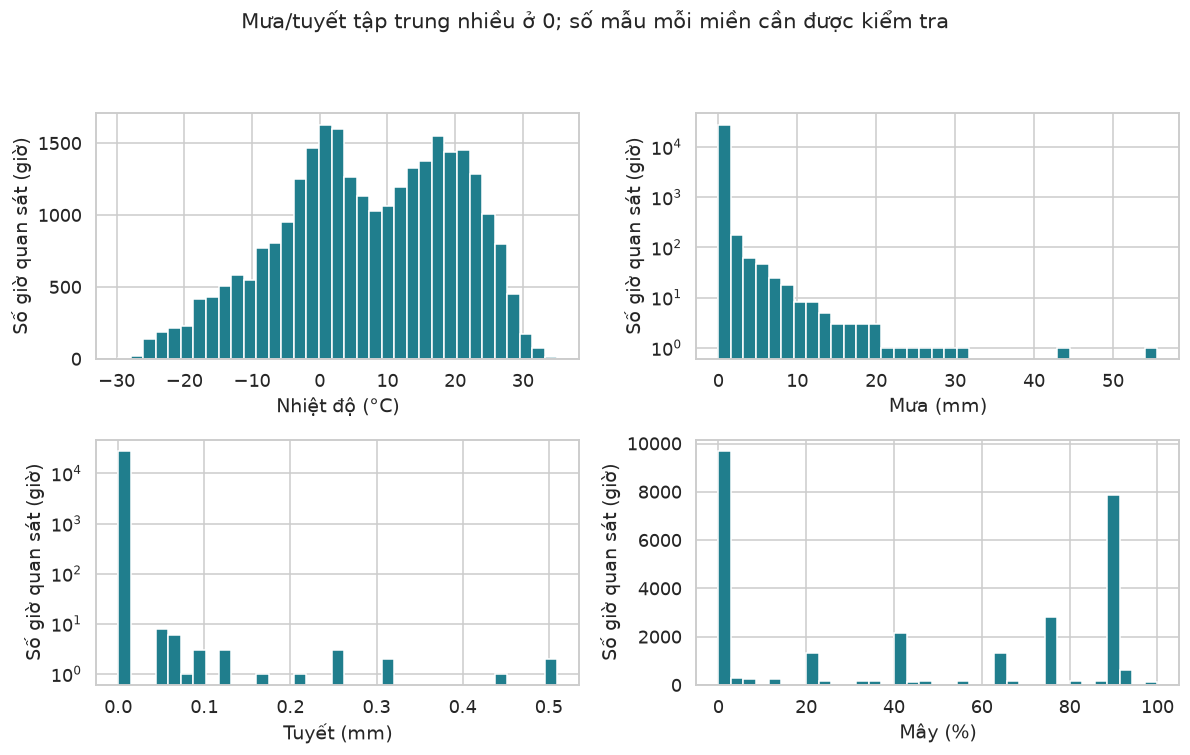

Trục dọc mưa/tuyết dùng log để thấy nhóm ít mẫu. Biểu đồ dùng giá trị sau mask bất thường, chưa điền thiếu; xem tỷ lệ thiếu trong bảng.

In [10]:
weather_numeric = ['temp_c', 'rain_1h', 'snow_1h', 'clouds_all']
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
units = ['Nhiệt độ (°C)', 'Mưa (mm)', 'Tuyết (mm)', 'Mây (%)']
for ax, f, label in zip(axes.flat, weather_numeric, units):
    ax.hist(train[f].dropna(), bins=35, color='#207E8D')
    ax.set(xlabel=label, ylabel='Số giờ quan sát (giờ)')
    if f in ['rain_1h', 'snow_1h']:
        ax.set_yscale('log')
eda_tools.figure(context, 'B', 1, 'weather_distribution', fig, 'Mưa/tuyết tập trung nhiều ở 0; số mẫu mỗi miền cần được kiểm tra', 'Trục dọc mưa/tuyết dùng log để thấy nhóm ít mẫu. Biểu đồ dùng giá trị sau mask bất thường, chưa điền thiếu; xem tỷ lệ thiếu trong bảng.')

## 5. Quan hệ với mục tiêu

In [11]:
weather_relations = eda_tools.continuous_relation(train, weather_numeric)
display(weather_relations)
display(Markdown('Pearson thấp chỉ nói liên hệ tuyến tính riêng lẻ yếu; Spearman mô tả liên hệ đơn điệu. Cả hai chưa đánh giá giá trị dự đoán bổ sung sau khi đã biết A12 và không chứng minh nhân quả.'))

,feature,Pearson,Spearman,n
0,temp_c,0.138954,0.137280,28392
1,rain_1h,-0.016084,0.008969,28401
2,snow_1h,-0.002164,-0.005694,28402
3,clouds_all,0.043598,0.036893,28402


Pearson thấp chỉ nói liên hệ tuyến tính riêng lẻ yếu; Spearman mô tả liên hệ đơn điệu. Cả hai chưa đánh giá giá trị dự đoán bổ sung sau khi đã biết A12 và không chứng minh nhân quả.

In [12]:
weather_bins = {f: eda_tools.binned(train, f) for f in weather_numeric}
for frame in weather_bins.values():
    display(frame)

,bin,mean,n,feature,small_group
0,"(-29.77, -6.00]",2924.238336,4737,temp_c,False
1,"(-6.00, 0.97]",3084.586382,4729,temp_c,False
2,"(0.97, 7.37]",3278.493449,4732,temp_c,False
3,"(7.37, 14.94]",3211.777214,4731,temp_c,False
4,"(14.94, 20.94]",3111.992602,4731,temp_c,False
5,"(20.94, 35.09]",3980.852705,4732,temp_c,False


,bin,mean,n,feature,small_group
0,0,3260.105354,26748,rain_1h,False
1,"(0.11, 0.25]",3473.215812,468,rain_1h,False
2,"(0.25, 0.51]",3493.495957,371,rain_1h,False
3,"(0.51, 1.41]",3416.168317,404,rain_1h,False
4,"(1.41, 55.63]",2957.980488,410,rain_1h,False


,bin,mean,n,feature,small_group
0,0,3265.002185,28371,snow_1h,False
1,"(0.04, 0.06]",2388.375000,8,snow_1h,True
2,"(0.06, 0.10]",2815.900000,10,snow_1h,True
3,"(0.10, 0.23]",2972.600000,5,snow_1h,True
4,"(0.23, 0.51]",3472.875000,8,snow_1h,True


,bin,mean,n,feature,small_group
0,"(-0.01, 1.00]",3012.766012,9680,clouds_all,False
1,"(1.00, 40.00]",3649.177032,4824,clouds_all,False
2,"(40.00, 75.00]",3371.368622,4704,clouds_all,False
3,"(75.00, 90.00]",3269.040987,8393,clouds_all,False
4,"(90.00, 100.00]",3318.483146,801,clouds_all,False


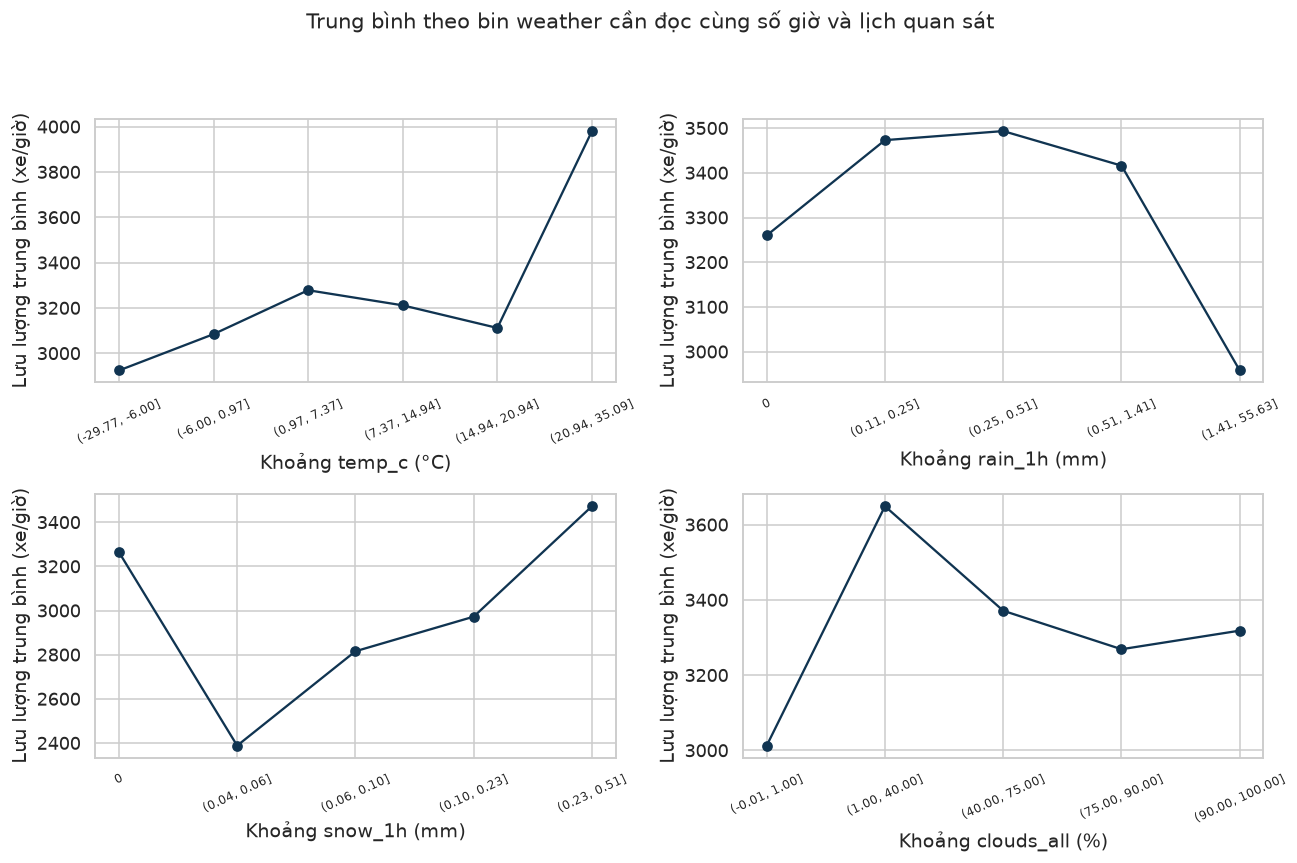

Mưa/tuyết tách bin 0 và các bin quantile của giá trị dương; bin có thể ít mẫu. So mức trung bình cùng n; chưa điều chỉnh giờ, mùa hoặc ngày lễ.

In [13]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, f in zip(axes.flat, weather_numeric):
    z = weather_bins[f]
    ax.plot(range(len(z)), z['mean'], marker='o', color='#103451')
    ax.set(xticks=range(len(z)), xticklabels=z.bin.astype(str), xlabel=f"Khoảng {f} ({dict(temp_c='°C', rain_1h='mm', snow_1h='mm', clouds_all='%')[f]})", ylabel='Lưu lượng trung bình (xe/giờ)')
    ax.tick_params(axis='x', labelrotation=25, labelsize=8)
eda_tools.figure(context, 'B', 2, 'weather_bins', fig, 'Trung bình theo bin weather cần đọc cùng số giờ và lịch quan sát', 'Mưa/tuyết tách bin 0 và các bin quantile của giá trị dương; bin có thể ít mẫu. So mức trung bình cùng n; chưa điều chỉnh giờ, mùa hoặc ngày lễ.')

Bootstrap lấy lại các khối 7 ngày để ước lượng khoảng tin cậy. Nhóm ít mẫu cần đọc thận trọng.

In [14]:
weather_effects = pd.DataFrame([eda_tools.binary_effect(train, f) for f in weather_flags])
display(weather_effects)

,feature,n0,n1,mean_difference,ci_low,ci_high,bootstrap_valid,small_group,n
0,weather_clear,19267,9135,-244.519548,-337.372719,-159.050596,400,False,28402
1,weather_clouds,17273,11129,387.083678,304.142404,466.241087,400,False,28402
2,weather_drizzle,27241,1161,-92.838491,-263.517059,84.315076,400,False,28402
3,weather_fog,27835,567,-534.674964,-816.961278,-211.629829,400,False,28402
4,weather_haze,27507,895,393.078508,187.054697,580.309113,400,False,28402
5,weather_mist,24391,4011,-378.756284,-483.077355,-274.167703,400,False,28402
6,weather_rain,24614,3788,23.198011,-69.127007,128.683508,400,False,28402
7,weather_smoke,28385,17,-328.624445,-1759.608368,1277.992983,346,True,28402
8,weather_snow,26413,1989,-269.935206,-400.957340,-120.127877,400,False,28402
9,weather_squall,28398,4,-1203.023646,-2864.453078,950.583121,393,True,28402


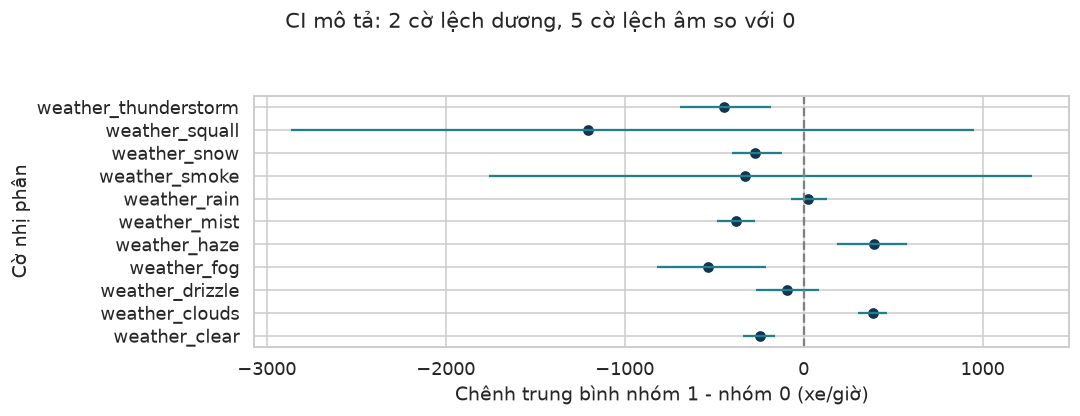

Điểm là chênh trung bình, đoạn ngang là CI bootstrap khối 7 ngày 95%. Đọc cùng n0/n1; nhóm quá ít mẫu hoặc không có biến thiên không cho CI đáng tin cậy. Chênh này chưa điều chỉnh lịch và không chứng minh tác động nhân quả.

In [15]:
eda_tools.binary_plot(context, 'B', weather_effects, 3)

VIF giúp nhận diện feature trùng thông tin tuyến tính; không dùng riêng chỉ số này để bỏ cột.

In [16]:
corr_b, vif_b = eda_tools.correlation_and_vif(train, CONFIG_B)
display(vif_b)

,feature,VIF,note,n
0,hour,2.561879,chưa vượt ngưỡng mô tả 5,28391
1,day_of_week,8.604578,đa cộng tuyến tuyến tính,28391
2,month,2.679108,chưa vượt ngưỡng mô tả 5,28391
3,is_weekend,8.277910,đa cộng tuyến tuyến tính,28391
4,is_rush_hour,1.177856,chưa vượt ngưỡng mô tả 5,28391
5,hour_sin,2.738533,chưa vượt ngưỡng mô tả 5,28391
6,hour_cos,1.156368,chưa vượt ngưỡng mô tả 5,28391
7,day_of_week_sin,2.897054,chưa vượt ngưỡng mô tả 5,28391
8,day_of_week_cos,3.209727,chưa vượt ngưỡng mô tả 5,28391
9,month_sin,2.624902,chưa vượt ngưỡng mô tả 5,28391


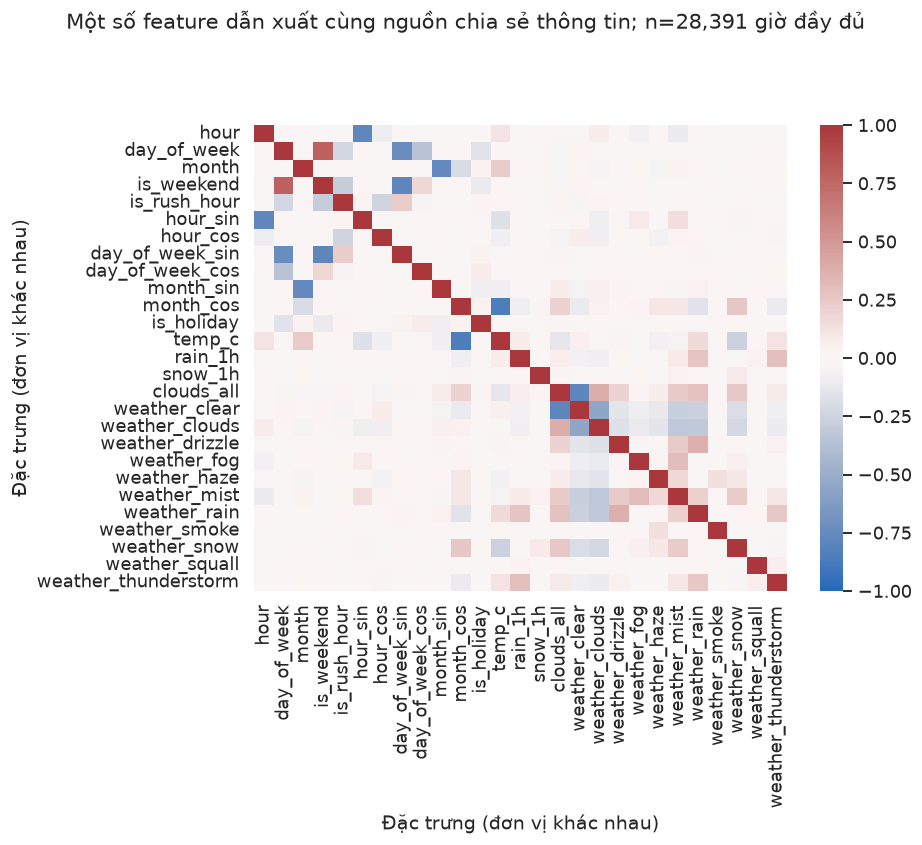

Màu thể hiện Pearson giữa các feature, không dùng để đánh giá liên hệ của mã giờ/thứ/tháng thô với target. Ô trống là hệ số không xác định, thường do biến hằng; không tự bỏ feature chỉ từ hình này.

In [17]:
eda_tools.corr_plot(context, 'B', corr_b, 4, len(train[CONFIG_B].dropna()))

## 6. Rủi ro rò rỉ và độ ổn định

In [18]:
display(eda_tools.stability(train, weather_numeric + weather_flags))

,year,feature,mean,missing_pct,n
0,2012,temp_c,1.716360,0.0,2103
1,2012,rain_1h,0.000000,0.0,2103
2,2012,snow_1h,0.000000,0.0,2103
3,2012,clouds_all,60.843557,0.0,2103
4,2012,weather_clear,0.182596,0.0,2103
...,...,...,...,...,...
85,2017,weather_rain,0.110316,0.0,3073
86,2017,weather_smoke,0.000000,0.0,3073
87,2017,weather_snow,0.095672,0.0,3073
88,2017,weather_squall,0.000000,0.0,3073


Weather cùng giờ được giả định đã biết. Nếu dự báo trước giờ đó, cần đầu vào dự báo thời tiết và đánh giá lại. Giữ quy tắc đánh dấu 0 K và điểm mưa nghi vấn; chưa tự xóa nhiệt độ lặp vì chưa rõ nguyên nhân.

In [19]:
fit_only_vocabulary = []
for fold, (fit_idx, score_idx) in enumerate(TimeSeriesSplit(n_splits=3).split(train), 1):
    raw_fit = context['raw'].loc[context['raw'].date_time.le(train.iloc[fit_idx].date_time.max())]
    raw_score = context['raw'].loc[context['raw'].date_time.between(train.iloc[score_idx].date_time.min(), train.iloc[score_idx].date_time.max())]
    fit_labels = set(raw_fit.weather_main.str.lower())
    fit_only_vocabulary.append(dict(fold=fold, labels_only_in_score=', '.join(sorted(set(raw_score.weather_main.str.lower()) - fit_labels)), n=len(raw_score)))
display(pd.DataFrame(fit_only_vocabulary))

,fold,labels_only_in_score,n
0,1,smoke,7870
1,2,,8590
2,3,,8545


## 7. Quyết định

Các biến thời tiết có phân phối lệch và một số nhãn ít mẫu. Có dòng mang nhãn Rain dù rain_1h bằng 0; cần phân biệt nhãn hiện tượng và lượng mưa đo trong giờ.

Đề xuất ba phương án: thêm thời tiết số, thêm cờ thời tiết và kết hợp cả hai. Pearson thấp chưa đủ để bỏ thời tiết; hiệu quả dự đoán được kiểm tra bằng RF cố định trong phần FE.

[Tài liệu API](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.TimeSeriesSplit.html): TimeSeriesSplit mở rộng phần train; khi giờ bị thiếu, các fold cùng số hàng chưa chắc có cùng thời lượng lịch.
[pandas rolling](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.rolling.html) mô tả cửa sổ thời gian và `closed="left"`.
[Định nghĩa VIF](https://www.statsmodels.org/stable/generated/statsmodels.stats.outliers_influence.variance_inflation_factor.html).